TASK 1

Word Types: 30
Word Tokens: 108000
Word Forms: 30
Lemmas: 30
Threshold: 1
Vocabulary Size: 30
UNK Percentage: 0.0
Threshold: 2
Vocabulary Size: 30
UNK Percentage: 0.0
Threshold: 3
Vocabulary Size: 30
UNK Percentage: 0.0
Threshold: 5
Vocabulary Size: 30
UNK Percentage: 0.0


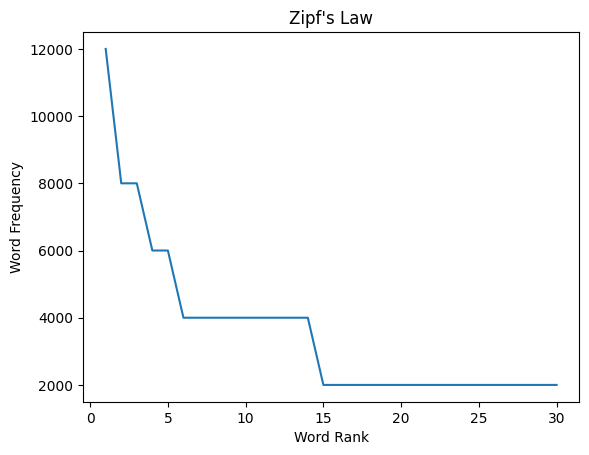

In [1]:
import re
import nltk
import random
import math
import collections
import matplotlib.pyplot as plt
random.seed(42)
sentences = [
    "two tickets to Vellore",
    "book a bus ticket to Chennai",
    "what is the train fare to Madurai",
    "bus timing from Chennai to Vellore",
    "I want to book a return ticket",
    "when does the train arrive",
    "cancel my bus ticket",
    "what is the refund amount",
    "the bus leaves at 6:30",
    "book two tickets to Madurai"
] * 2000
def tokenize(sentence):
    return re.findall(r"\d+:\d+|\w+", sentence.lower())
tokens = [tokenize(s) for s in sentences]
all_words = [word for sentence in tokens for word in sentence]
types = set(all_words)
word_tokens = len(all_words)
print("Word Types:", len(types))
print("Word Tokens:", word_tokens)
print("Word Forms:", len(types))
print("Lemmas:", len(set(all_words)))
for threshold in [1, 2, 3, 5]:
    freq = collections.Counter(all_words)
    vocab = {w for w, c in freq.items() if c >= threshold}
    unk = sum(c for w, c in freq.items() if c < threshold)
    print("Threshold:", threshold)
    print("Vocabulary Size:", len(vocab))
    print("UNK Percentage:", unk / word_tokens * 100)
freq = collections.Counter(all_words)
ranked = sorted(freq.values(), reverse=True)
plt.plot(range(1, len(ranked) + 1), ranked)
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("Zipf's Law")
plt.show()

TASK 2

In [2]:
from collections import Counter
train = tokens[:16000]
dev = tokens[16000:18000]
test = tokens[18000:]
unigram = Counter()
bigram = Counter()
trigram = Counter()
for sentence in train:
    words = ["<s>"] + sentence + ["</s>"]
    unigram.update(words)
    bigram.update(zip(words[:-1], words[1:]))
    trigram.update(zip(words[:-2], words[1:-1], words[2:]))
def unigram_prob(word):
    return unigram[word] / sum(unigram.values())
def bigram_prob(w1, w2):
    return bigram[(w1, w2)] / unigram[w1] if unigram[w1] else 0
def trigram_prob(w1, w2, w3):
    count = trigram[(w1, w2, w3)]
    context = bigram[(w1, w2)]
    return count / context if context else 0
print("Unigram Probability:", unigram_prob("tickets"))
print("Bigram Probability:", bigram_prob("to", "vellore"))
print("Trigram Probability:", trigram_prob("two", "tickets", "to"))
possible_bigrams = len(unigram) ** 2
possible_trigrams = len(unigram) ** 3
print("Bigram Sparsity:", len(bigram) / possible_bigrams)
print("Trigram Sparsity:", len(trigram) / possible_trigrams)
dev_words = [w for s in dev for w in s]
oov = sum(1 for w in dev_words if w not in unigram)
print("Development OOV Rate:", oov / len(dev_words))
def generate_bigram():
    current = "<s>"
    result = []
    for _ in range(10):
        choices = [(b, c) for (a, b), c in bigram.items() if a == current]
        if not choices:
            break
        words, counts = zip(*choices)
        current = random.choices(words, weights=counts)[0]
        if current == "</s>":
            break
        result.append(current)
    return " ".join(result)

for i in range(10):
    print(generate_bigram())

Unigram Probability: 0.02702702702702703
Bigram Probability: 0.3333333333333333
Trigram Probability: 1.0
Bigram Sparsity: 0.048828125
Trigram Sparsity: 0.001495361328125
Development OOV Rate: 0.0
i want to vellore
i want to chennai
book a bus ticket
bus ticket
cancel my bus timing from chennai to chennai
two tickets to madurai
bus leaves at 6:30
i want to madurai
book a bus ticket to vellore
what is the train arrive


TASK 3

In [3]:
V = len(unigram)
k = 0.5
def laplace(w1, w2):
    return (bigram[(w1, w2)] + 1) / (unigram[w1] + V)
def add_k(w1, w2):
    return (bigram[(w1, w2)] + k) / (unigram[w1] + k * V)
print("Laplace Probability:", laplace("to", "vellore"))
print("Add-k Probability:", add_k("to", "vellore"))
context = "to"
for word in unigram:
    count = bigram[(context, word)]
    probability = (count + 1) / (unigram[context] + V)
    print(word, count, probability)
frequency_of_frequencies = Counter(bigram.values())
def good_turing(count):
    nr = frequency_of_frequencies[count]
    nr1 = frequency_of_frequencies[count + 1]
    if nr > 0 and nr1 > 0:
        return (count + 1) * nr1 / nr
    return count
for count in sorted(frequency_of_frequencies):
    print(count, good_turing(count))
N1 = frequency_of_frequencies[1]
N = sum(bigram.values())
print("Unseen Bigram Probability Mass:", N1 / N)

Laplace Probability: 0.3323297342192691
Add-k Probability: 0.33283069883527455
<s> 0 0.00010382059800664452
two 0 0.00010382059800664452
tickets 0 0.00010382059800664452
to 0 0.00010382059800664452
vellore 3200 0.3323297342192691
</s> 0 0.00010382059800664452
book 1600 0.16621677740863788
a 0 0.00010382059800664452
bus 0 0.00010382059800664452
ticket 0 0.00010382059800664452
chennai 1600 0.16621677740863788
what 0 0.00010382059800664452
is 0 0.00010382059800664452
the 0 0.00010382059800664452
train 0 0.00010382059800664452
fare 0 0.00010382059800664452
madurai 3200 0.3323297342192691
timing 0 0.00010382059800664452
from 0 0.00010382059800664452
i 0 0.00010382059800664452
want 0 0.00010382059800664452
return 0 0.00010382059800664452
when 0 0.00010382059800664452
does 0 0.00010382059800664452
arrive 0 0.00010382059800664452
cancel 0 0.00010382059800664452
my 0 0.00010382059800664452
refund 0 0.00010382059800664452
amount 0 0.00010382059800664452
leaves 0 0.00010382059800664452
at 0 0.000

TASK 4

In [4]:
import numpy as np
vocab = list(unigram.keys())
V = len(vocab)
def unigram_p(w):
    return (unigram[w] + 1) / (sum(unigram.values()) + V)
def bigram_p(w1, w2):
    return (bigram[(w1, w2)] + 1) / (unigram[w1] + V)
def trigram_p(w1, w2, w3):
    return (trigram[(w1, w2, w3)] + 1) / (bigram[(w1, w2)] + V)
def stupid_backoff(w1, w2, w3):
    if trigram[(w1, w2, w3)] > 0:
        return trigram[(w1, w2, w3)] / bigram[(w1, w2)]
    if bigram[(w2, w3)] > 0:
        return 0.4 * bigram[(w2, w3)] / unigram[w2]
    return 0.4 * 0.4 * unigram_p(w3)
lambdas = [0.2, 0.3, 0.5]
def interpolation(w1, w2, w3):
    return (
        lambdas[0] * unigram_p(w3)
        + lambdas[1] * bigram_p(w2, w3)
        + lambdas[2] * trigram_p(w1, w2, w3)
    )
def deleted_interpolation():
    counts = [0, 0, 0]
    for sentence in train:
        words = ["<s>"] + sentence + ["</s>"]
        for i in range(2, len(words)):
            w1, w2, w3 = words[i-2:i+1]
            scores = [
                (unigram[w3] - 1) / max(1, sum(unigram.values()) - 1),
                (bigram[(w2, w3)] - 1) / max(1, unigram[w2] - 1),
                (trigram[(w1, w2, w3)] - 1) / max(1, bigram[(w1, w2)] - 1)
            ]
            counts[scores.index(max(scores))] += 1
    total = sum(counts)
    return [c / total for c in counts]
lambdas = deleted_interpolation()
print("Deleted Interpolation Weights:", lambdas)
print("Stupid Backoff:", stupid_backoff("two", "tickets", "to"))
print("Linear Interpolation:", interpolation("two", "tickets", "to"))

Deleted Interpolation Weights: [0.0, 0.6481481481481481, 0.35185185185185186]
Stupid Backoff: 1.0
Linear Interpolation: 0.9904084158415841


TASK 5

In [5]:
def entropy(probabilities):
    return -sum(p * math.log2(p) for p in probabilities if p > 0)
print("Uniform Entropy:", entropy([0.25, 0.25, 0.25, 0.25]))
print("Peaked Entropy:", entropy([0.9, 0.05, 0.03, 0.02]))
def perplexity(sentences, model="bigram"):
    log_sum = 0
    count = 0
    for sentence in sentences:
        words = ["<s>"] + sentence + ["</s>"]
        for i in range(1, len(words)):
            if model == "bigram":
                p = bigram_p(words[i-1], words[i])
            else:
                p = unigram_p(words[i])
            log_sum += math.log(p)
            count += 1
    cross_entropy = -log_sum / count
    return cross_entropy, math.exp(cross_entropy)
for model in ["unigram", "bigram"]:
    ce, pp = perplexity(dev, model)
    print(model, "Cross Entropy:", ce)
    print(model, "Perplexity:", pp)

Uniform Entropy: 2.0
Peaked Entropy: 0.6175431233120147
unigram Cross Entropy: 3.3050469467388073
unigram Perplexity: 27.249820848994254
bigram Cross Entropy: 0.7048653953684365
bigram Perplexity: 2.023574284118599


TASK 6

In [9]:
import nltk
from collections import Counter
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt_tab', quiet=True)
sentences = [
    "two tickets to Vellore",
    "book a bus ticket to Chennai",
    "what is the train fare to Madurai",
    "I want to book a return ticket",
    "cancel my bus ticket"
]
mapping = {
    "NN": "NOUN", "NNS": "NOUN", "NNP": "PROPN",
    "VB": "VERB", "VBD": "VERB", "VBG": "VERB",
    "VBN": "VERB", "VBP": "VERB", "VBZ": "VERB",
    "JJ": "ADJ", "RB": "ADV", "PRP": "PRON",
    "DT": "DET", "IN": "ADP", "CC": "CONJ",
    "CD": "NUM", "MD": "AUX", "TO": "PART"
}
tagged = []
for s in sentences:
    words = nltk.word_tokenize(s)
    tagged.append([(w, mapping.get(t, "OTHER")) for w, t in nltk.pos_tag(words)])
print("Tagged Data:")
for s in tagged:
    print(s)
freq = Counter(t for s in tagged for w, t in s)
print("\nTag Frequency:", freq)
print("Total Tokens:", sum(freq.values()))


Tagged Data:
[('two', 'NUM'), ('tickets', 'NOUN'), ('to', 'PART'), ('Vellore', 'VERB')]
[('book', 'NOUN'), ('a', 'DET'), ('bus', 'NOUN'), ('ticket', 'NOUN'), ('to', 'PART'), ('Chennai', 'VERB')]
[('what', 'OTHER'), ('is', 'VERB'), ('the', 'DET'), ('train', 'NOUN'), ('fare', 'NOUN'), ('to', 'PART'), ('Madurai', 'PROPN')]
[('I', 'PRON'), ('want', 'VERB'), ('to', 'PART'), ('book', 'NOUN'), ('a', 'DET'), ('return', 'NOUN'), ('ticket', 'NOUN')]
[('cancel', 'NOUN'), ('my', 'OTHER'), ('bus', 'NOUN'), ('ticket', 'NOUN')]

Tag Frequency: Counter({'NOUN': 12, 'PART': 4, 'VERB': 4, 'DET': 3, 'OTHER': 2, 'NUM': 1, 'PROPN': 1, 'PRON': 1})
Total Tokens: 28


TASK 7

In [10]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize
def rule_tagger(sentence):
    words = word_tokenize(sentence)
    tagged = []
    for i, word in enumerate(words):
        w = word.lower()
        if w in ["to", "from", "in", "at", "on"]:
            tag = "ADP"
        elif w in ["a", "an", "the", "my"]:
            tag = "DET"
        elif w in ["is", "are", "was", "book", "cancel", "return"]:
            tag = "VERB"
        elif w.endswith("ly"):
            tag = "ADV"
        elif w.isdigit():
            tag = "NUM"
        elif word[0].isupper():
            tag = "PROPN"
        else:
            tag = "NOUN"
        tagged.append((word, tag))
    return tagged
for sentence in sentences[:10]:
    print(sentence)
    print(rule_tagger(sentence))

two tickets to Vellore
[('two', 'NOUN'), ('tickets', 'NOUN'), ('to', 'ADP'), ('Vellore', 'PROPN')]
book a bus ticket to Chennai
[('book', 'VERB'), ('a', 'DET'), ('bus', 'NOUN'), ('ticket', 'NOUN'), ('to', 'ADP'), ('Chennai', 'PROPN')]
what is the train fare to Madurai
[('what', 'NOUN'), ('is', 'VERB'), ('the', 'DET'), ('train', 'NOUN'), ('fare', 'NOUN'), ('to', 'ADP'), ('Madurai', 'PROPN')]
I want to book a return ticket
[('I', 'PROPN'), ('want', 'NOUN'), ('to', 'ADP'), ('book', 'VERB'), ('a', 'DET'), ('return', 'VERB'), ('ticket', 'NOUN')]
cancel my bus ticket
[('cancel', 'VERB'), ('my', 'DET'), ('bus', 'NOUN'), ('ticket', 'NOUN')]


TASK 8

In [12]:
import nltk
from collections import Counter
data = [nltk.pos_tag(s.split()) for s in [
    "two tickets to Vellore",
    "book a bus ticket",
    "cancel my bus ticket"
]]
tags = set(t for s in data for w, t in s)
trans, emit, count = Counter(), Counter(), Counter()
for s in data:
    prev = "<s>"
    for w, t in s:
        trans[prev, t] += 1
        emit[t, w.lower()] += 1
        count[t] += 1
        prev = t
def viterbi(words):
    dp = [{}]
    back = [{}]
    for t in tags:
        dp[0][t] = trans["<s>", t] + 1
        back[0][t] = None
    for i in range(1, len(words)):
        dp.append({})
        back.append({})
        for t in tags:
            scores = [(dp[i-1][p] * (trans[p, t] + 1) *
                       (emit[t, words[i]] + 1), p) for p in tags]
            dp[i][t], back[i][t] = max(scores)
    best = max(tags, key=lambda t: dp[-1][t])
    result = [best]
    for i in range(len(words)-1, 0, -1):
        best = back[i][best]
        result.append(best)
    return list(zip(words, result[::-1]))
print(viterbi(["two", "tickets", "to", "vellore"]))

[('two', 'CD'), ('tickets', 'NNS'), ('to', 'TO'), ('vellore', 'VB')]


TASK 9

In [15]:
import nltk
from nltk.tag import UnigramTagger, BrillTaggerTrainer
from nltk.tag.brill import Template, Pos, Word
data = [
    nltk.pos_tag(s.split()) for s in [
        "two tickets to Vellore",
        "book a bus ticket",
        "cancel my bus ticket",
        "the train arrives today",
        "I want to book tickets",
        "the bus leaves tomorrow",
        "please cancel my return ticket",
        "when does the train arrive",
        "book two tickets to Chennai",
        "my bus is late"
    ]
]
train = data[:7]
test = data[7:]
templates = [
    Template(Pos([-1])),
    Template(Pos([1])),
    Template(Word([-1])),
    Template(Word([1]))
]
initial = UnigramTagger(train)
trainer = BrillTaggerTrainer(initial, templates, trace=0)
tagger = trainer.train(train, max_rules=10)
print("Rules:")
for r in tagger.rules():
    print(r)
print("Test Accuracy:", tagger.accuracy(test))

Rules:
Test Accuracy: 0.5714285714285714


In [ ]:
TASK 10

In [17]:
import nltk
import time
import sys
from collections import Counter
data = [
    "two tickets to vellore",
    "book a bus ticket",
    "cancel my bus ticket",
    "train arrives today",
    "book tickets to chennai"
]
start = time.time()
tokens = [s.split() for s in data]
words = [w for s in tokens for w in s]
unigram = Counter(words)
bigram = Counter(
    (s[i], s[i+1])
    for s in tokens for i in range(len(s)-1)
)
print("Unigram:", unigram)
print("Bigram:", bigram)
print("Unigram Size:", sys.getsizeof(unigram))
print("Bigram Size:", sys.getsizeof(bigram))
print("Execution Time:", time.time()-start)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
tagged = [nltk.pos_tag(s) for s in tokens]
print("POS Tags:")
for s in tagged:
    print(s)
print("Total Tokens:", len(words))

Unigram: Counter({'tickets': 2, 'to': 2, 'book': 2, 'bus': 2, 'ticket': 2, 'two': 1, 'vellore': 1, 'a': 1, 'cancel': 1, 'my': 1, 'train': 1, 'arrives': 1, 'today': 1, 'chennai': 1})
Bigram: Counter({('tickets', 'to'): 2, ('bus', 'ticket'): 2, ('two', 'tickets'): 1, ('to', 'vellore'): 1, ('book', 'a'): 1, ('a', 'bus'): 1, ('cancel', 'my'): 1, ('my', 'bus'): 1, ('train', 'arrives'): 1, ('arrives', 'today'): 1, ('book', 'tickets'): 1, ('to', 'chennai'): 1})
Unigram Size: 480
Bigram Size: 648
Execution Time: 0.003118753433227539
POS Tags:
[('two', 'CD'), ('tickets', 'NNS'), ('to', 'TO'), ('vellore', 'VB')]
[('book', 'NN'), ('a', 'DT'), ('bus', 'NN'), ('ticket', 'NN')]
[('cancel', 'NN'), ('my', 'PRP$'), ('bus', 'NN'), ('ticket', 'NN')]
[('train', 'NN'), ('arrives', 'NNS'), ('today', 'NN')]
[('book', 'NN'), ('tickets', 'NNS'), ('to', 'TO'), ('chennai', 'VB')]
Total Tokens: 19


TASK 12

In [18]:
import random
from collections import Counter
random.seed(42)
train = [
    "two tickets to vellore",
    "book a bus ticket",
    "cancel my bus ticket",
    "train arrives today",
    "bus timing to chennai"
]
new_data = [
    "chennai to madurai bus timing enna",
    "book ticket to tambaram",
    "train timing to vellore",
    "madurai bus fare sollunga"
]
words = [w for s in train for w in s.split()]
vocab = set(words)
def predict(sentence):
    result = []
    for w in sentence.split():
        if w in vocab:
            result.append(w)
        else:
            result.append("<UNK>")
    return result
print("Original Vocabulary:", vocab)
for s in new_data:
    print("\nInput:", s)
    print("Original Model:", predict(s))
stations = {"chennai", "madurai", "vellore", "tambaram"}
def adapted(sentence):
    result = []
    for w in sentence.lower().split():
        if w in stations:
            result.append("STATION")
        elif w in vocab:
            result.append(w)
        else:
            result.append("<UNK>")
    return result
for s in new_data:
    print("\nInput:", s)
    print("Adapted Model:", adapted(s))
new_vocab = vocab.union(stations)\
print("\nOriginal Vocabulary Size:", len(vocab))
print("Updated Vocabulary Size:", len(new_vocab))
print("New Words:", new_vocab - vocab)

Original Vocabulary: {'vellore', 'cancel', 'chennai', 'book', 'tickets', 'ticket', 'train', 'arrives', 'my', 'to', 'two', 'bus', 'today', 'a', 'timing'}

Input: chennai to madurai bus timing enna
Original Model: ['chennai', 'to', '<UNK>', 'bus', 'timing', '<UNK>']

Input: book ticket to tambaram
Original Model: ['book', 'ticket', 'to', '<UNK>']

Input: train timing to vellore
Original Model: ['train', 'timing', 'to', 'vellore']

Input: madurai bus fare sollunga
Original Model: ['<UNK>', 'bus', '<UNK>', '<UNK>']

Input: chennai to madurai bus timing enna
Adapted Model: ['STATION', 'to', 'STATION', 'bus', 'timing', '<UNK>']

Input: book ticket to tambaram
Adapted Model: ['book', 'ticket', 'to', 'STATION']

Input: train timing to vellore
Adapted Model: ['train', 'timing', 'to', 'STATION']

Input: madurai bus fare sollunga
Adapted Model: ['STATION', 'bus', '<UNK>', '<UNK>']

Original Vocabulary Size: 15
Updated Vocabulary Size: 17
New Words: {'tambaram', 'madurai'}
